In [1]:
import pandas as pd
import numpy as np
import os
import neurokit2 as nk
from ecg_preprocess import find_patient_ecg_path, process_ecg_files

In [2]:
def save_ecg_per_patient(patient, window_second=20, lead=1, end_minute=30):
    """
    Save the ECG segments of a patient into a csv file
    Args:
        patient (int): the patient ID
        window_second (int): the length of the window in seconds
        lead (int): the ECG lead to be used
        end_minute (int): the end minute of the ECG segment
    Returns:
        qualified signal segments
    """
    base_path = '../data/01NVa_Sepsis/RAW_DATA/'
    ecg_path = find_patient_ecg_path(base_path, patient)
    ecg_files = process_ecg_files(ecg_path, lead=lead)
    if ecg_files is None:
        return None
    ecg_data, sampling_rate = ecg_files
    window_size = int(window_second * sampling_rate)
    end_index = int(end_minute * 60 * sampling_rate)
    qualified_segments = {}
    for i in range(0, end_index, window_size):
        try:
            segment = ecg_data[i:i+window_size]
            if len(segment) < window_size:
                continue
            # Clean the ECG signal
            ecg_signal = nk.ecg_clean(segment, sampling_rate=sampling_rate)
            
            quality = nk.ecg_quality(segment, sampling_rate=sampling_rate, method='zhao2018')
            if quality == 'Unacceptable':
                continue
            time_elapsed = int(i / sampling_rate)
            qualified_segments[time_elapsed] = ecg_signal
        except:
            continue
    if len(qualified_segments) == 0:
        return None
    else:
        return {'signals': qualified_segments, 'sampling_rate': sampling_rate}


In [ ]:
import pickle
def save_ecg_segments(window_second=20, lead=1, end_minute=60):
    ecg_all = {}
    for i in range(1001, 1260):
        res = save_ecg_per_patient(f"003-{i}", window_second=window_second, lead=lead, end_minute=end_minute)
        if res is not None:
            ecg_all[f"003-{i}"] = res
    with open(f'../data/ecg_segments_{window_second}s_lead{lead}_end{end_minute}min.pkl', 'wb') as f:
        pickle.dump(ecg_all, f)

In [ ]:
# save_ecg_segments(window_second=20, lead=1, end_minute=60)

Patient 003-1021 found but no ECG data found in ../data/01NVa_Sepsis/RAW_DATA/01NVa-003-1021 - no data, ward transfer early/ePatch/Extracted (from EDF converter).
Patient 003-1026 found but no ECG data found in ../data/01NVa_Sepsis/RAW_DATA/01NVa-003-1026/ePatch/Extracted (from EDF converter).
Patient 003-1047 not found.
Patient 003-1048 not found.
Patient 003-1049 not found.
Patient 003-1050 not found.
Patient 003-1051 not found.
Patient 003-1052 not found.
Patient 003-1053 not found.
Patient 003-1054 not found.
Patient 003-1055 not found.
Patient 003-1056 not found.
Patient 003-1057 not found.
Patient 003-1058 not found.
Patient 003-1059 not found.
Patient 003-1060 not found.
Patient 003-1061 not found.
Patient 003-1062 not found.
Patient 003-1063 not found.
Patient 003-1064 not found.
Patient 003-1065 not found.
Patient 003-1066 not found.
Patient 003-1067 not found.
Patient 003-1068 not found.
Patient 003-1069 not found.
Patient 003-1070 not found.
Patient 003-1071 not found.
Patie

In [ ]:
# Load the ECG segments
def load_ecg_segments(window_second=20, lead=1, end_minute=60):
    with open(f'../data/ecg_segments_{window_second}s_lead{lead}_end{end_minute}min.pkl', 'rb') as f:
        ecg_all = pickle.load(f)
    return ecg_all
ecg_all = load_ecg_segments(window_second=20, lead=1, end_minute=60)

In [ ]:
ecg_all.keys() # patient IDs

dict_keys(['003-1001', '003-1002', '003-1003', '003-1004', '003-1005', '003-1006', '003-1007', '003-1008', '003-1009', '003-1010', '003-1011', '003-1012', '003-1013', '003-1014', '003-1015', '003-1016', '003-1017', '003-1018', '003-1019', '003-1020', '003-1022', '003-1023', '003-1025', '003-1027', '003-1028', '003-1029', '003-1030', '003-1031', '003-1032', '003-1033', '003-1034', '003-1035', '003-1036', '003-1037', '003-1038', '003-1039', '003-1040', '003-1041', '003-1042', '003-1043', '003-1044', '003-1045', '003-1046', '003-1101', '003-1102', '003-1103', '003-1104', '003-1105', '003-1106', '003-1107', '003-1108', '003-1109', '003-1110', '003-1111', '003-1112', '003-1113', '003-1115', '003-1116', '003-1117', '003-1118', '003-1119', '003-1120', '003-1121', '003-1122', '003-1123', '003-1124', '003-1125', '003-1126', '003-1128', '003-1129', '003-1130', '003-1131', '003-1132', '003-1134', '003-1135', '003-1136', '003-1137', '003-1138', '003-1139', '003-1140', '003-1141', '003-1142', '003-

In [7]:
ecg_all['003-1001'].keys() # 'signals' and 'sampling_rate'

dict_keys(['signals', 'sampling_rate'])

In [8]:
ecg_all['003-1001']['signals'].keys() # time elapsed

dict_keys([20, 920, 1080, 1660, 1900, 2100, 2120, 2360, 2380, 2420, 2480, 2500, 2520, 2540, 2560, 2600, 2620, 2640, 2660, 2680, 2700, 2720, 2740, 2760, 2780, 2800, 2820, 2840, 2860, 2880, 2900, 2920, 2940, 2960, 2980, 3000, 3280, 3360, 3380])

In [10]:
ecg_all['003-1001']['signals'][920].shape # ECG signal

(5120,)

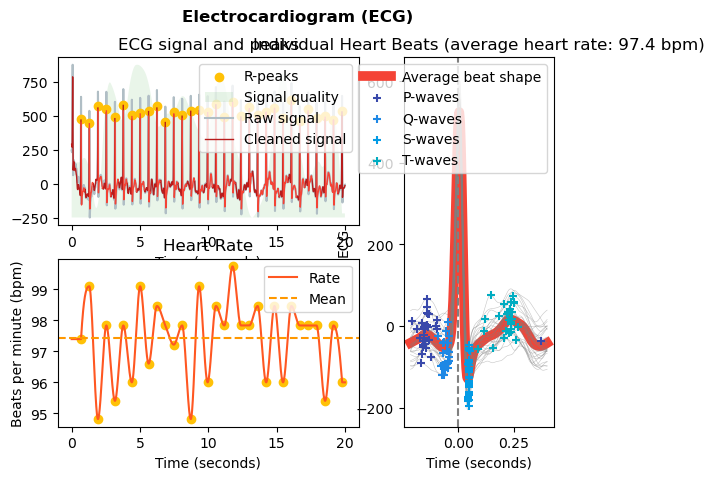

In [ ]:
# example plot
fs = ecg_all['003-1001']['sampling_rate']
signals, info = nk.ecg_process(ecg_all['003-1001']['signals'][920], sampling_rate=fs)
nk.ecg_plot(signals, info)